# Distributed Machine Learning: FedAvg Implementation
## Course Project

This notebook implements the Federated Averaging (FedAvg) algorithm from [McMahan et al., 2017](https://arxiv.org/pdf/1602.05629) and evaluates it on FashionMNIST and CIFAR-10 datasets.

**Structure:**
- Q1: Baseline centralized training (FashionMNIST)
- Q2: FedAvg with 5 simulated clients (FashionMNIST)
- Q3: Repeat Q1 & Q2 with CIFAR-10

**Key design decisions:**
- Client simulation: Per the project notes — *"To simulate multiple clients in one machine, you can create multiple threads or simply using iteration"* — clients are simulated via iteration
- Main process acts as the server for aggregation
- Validation set: Used by server to check convergence
- Test set: Evaluated by server every communication round for reporting
- Non-IID uneven split: Dirichlet distribution to divide data per label across clients with no overlap

## Setup & Imports

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import copy
import random

# Reproducibility
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## Model Definitions

In [29]:
class TwoLayerNN(nn.Module):
    """Improved but still lightweight MLP for FashionMNIST (28x28 grayscale)."""
    def __init__(self, input_dim=784, hidden_dim1=512, hidden_dim2=256, num_classes=10, dropout=0.2):
        super(TwoLayerNN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim2, num_classes),
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.net(x)
        return x


class SmallCNN_CIFAR(nn.Module):
    """
    Small CNN for CIFAR-10 (32x32x3 RGB).
    2 conv blocks + fully connected layers.
    Kept small per project requirement while achieving
    meaningful accuracy on CIFAR-10.
    """
    def __init__(self, num_classes=10):
        super(SmallCNN_CIFAR, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

## Data Loading

We split the original training set into **train** and **validation**.
- Train: used by clients for local training
- Validation: used by server to monitor convergence in FedAvg
- Test: evaluated by server every communication round for reporting curves

In [30]:
def load_fashionmnist(val_fraction=0.1):
    """Load FashionMNIST with train/val/test split."""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.2860,), (0.3530,))
    ])
    full_train = torchvision.datasets.FashionMNIST(
        root='./data', train=True, download=True, transform=transform
    )
    test_dataset = torchvision.datasets.FashionMNIST(
        root='./data', train=False, download=True, transform=transform
    )
    val_size = int(len(full_train) * val_fraction)
    train_size = len(full_train) - val_size
    train_dataset, val_dataset = random_split(
        full_train, [train_size, val_size],
        generator=torch.Generator().manual_seed(0)
    )
    return train_dataset, val_dataset, test_dataset, full_train


def load_cifar10(val_fraction=0.1):
    """Load CIFAR-10 with train/val/test split."""
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])
    full_train = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=transform
    )
    test_dataset = torchvision.datasets.CIFAR10(
        root='./data', train=False, download=True, transform=transform
    )
    val_size = int(len(full_train) * val_fraction)
    train_size = len(full_train) - val_size
    train_dataset, val_dataset = random_split(
        full_train, [train_size, val_size],
        generator=torch.Generator().manual_seed(0)
    )
    return train_dataset, val_dataset, test_dataset, full_train


# Download and split datasets
fashion_train, fashion_val, fashion_test, fashion_full = load_fashionmnist()
cifar_train, cifar_val, cifar_test, cifar_full = load_cifar10()

print(f'FashionMNIST - Train: {len(fashion_train)}, Val: {len(fashion_val)}, Test: {len(fashion_test)}')
print(f'CIFAR-10     - Train: {len(cifar_train)}, Val: {len(cifar_val)}, Test: {len(cifar_test)}')

FashionMNIST - Train: 54000, Val: 6000, Test: 10000
CIFAR-10     - Train: 45000, Val: 5000, Test: 10000


## Helper Functions: Training & Evaluation

In [7]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """Train model for one epoch. Returns average loss and accuracy."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for data, target in dataloader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * data.size(0)
        _, predicted = output.max(1)
        correct += predicted.eq(target).sum().item()
        total += data.size(0)
    return total_loss / total, correct / total * 100


def evaluate(model, dataloader, criterion, device):
    """Evaluate model on a dataset. Returns average loss and accuracy."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for data, target in dataloader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            loss = criterion(output, target)
            total_loss += loss.item() * data.size(0)
            _, predicted = output.max(1)
            correct += predicted.eq(target).sum().item()
            total += data.size(0)
    return total_loss / total, correct / total * 100

---
# Q1: Baseline Centralized Training (FashionMNIST)

Train the FashionMNIST baseline model on a single machine using the full training dataset.
In this optimized setup, we run **30 epochs** and repeat training **5 times**.
We report training and testing accuracy curves, plus the final converged model's mean accuracy and variance across runs.

In [32]:
def run_baseline(train_dataset, test_dataset, model_class, num_runs=5,
                 num_epochs=20, batch_size=64, lr=0.01, device='cpu',
                 optimizer_name='sgd', weight_decay=0.0, use_cosine_scheduler=False):
    """
    Baseline centralized training.
    Uses full training data. Reports accuracy on the test set.
    """
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    criterion = nn.CrossEntropyLoss()

    all_train_acc = []
    all_test_acc = []

    for run in range(num_runs):
        set_seed(run * 42)
        model = model_class().to(device)

        if optimizer_name.lower() == 'adamw':
            optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        else:
            optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)

        scheduler = None
        if use_cosine_scheduler:
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

        train_accs, test_accs = [], []
        for epoch in range(num_epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
            test_loss, test_acc = evaluate(model, test_loader, criterion, device)

            if scheduler is not None:
                scheduler.step()

            train_accs.append(train_acc)
            test_accs.append(test_acc)
            print(f'  Run {run+1}/{num_runs}, Epoch {epoch+1}/{num_epochs}: '
                  f'Train Acc: {train_acc:.2f}%, Test Acc: {test_acc:.2f}%')

        all_train_acc.append(train_accs)
        all_test_acc.append(test_accs)
        print(f'--- Run {run+1} Final: Train {train_accs[-1]:.2f}%, Test {test_accs[-1]:.2f}% ---\n')

    return np.array(all_train_acc), np.array(all_test_acc)

In [33]:
print('='*60)
print('Q1: Baseline Centralized Training - FashionMNIST (Improved Setup)')
print('='*60)
q1_train_acc, q1_test_acc = run_baseline(
    fashion_full, fashion_test, TwoLayerNN,
    num_runs=5, num_epochs=30, batch_size=128, lr=1e-3, device=device,
    optimizer_name='adamw', weight_decay=1e-4, use_cosine_scheduler=True
)

Q1: Baseline Centralized Training - FashionMNIST (Improved Setup)
  Run 1/5, Epoch 1/30: Train Acc: 82.13%, Test Acc: 85.39%
  Run 1/5, Epoch 2/30: Train Acc: 86.67%, Test Acc: 86.53%
  Run 1/5, Epoch 3/30: Train Acc: 87.51%, Test Acc: 87.03%
  Run 1/5, Epoch 4/30: Train Acc: 88.44%, Test Acc: 87.46%
  Run 1/5, Epoch 5/30: Train Acc: 89.11%, Test Acc: 87.88%
  Run 1/5, Epoch 6/30: Train Acc: 89.55%, Test Acc: 87.97%
  Run 1/5, Epoch 7/30: Train Acc: 90.05%, Test Acc: 87.87%
  Run 1/5, Epoch 8/30: Train Acc: 90.50%, Test Acc: 89.03%
  Run 1/5, Epoch 9/30: Train Acc: 90.77%, Test Acc: 88.82%
  Run 1/5, Epoch 10/30: Train Acc: 91.27%, Test Acc: 88.95%
  Run 1/5, Epoch 11/30: Train Acc: 91.75%, Test Acc: 89.12%
  Run 1/5, Epoch 12/30: Train Acc: 92.01%, Test Acc: 89.32%
  Run 1/5, Epoch 13/30: Train Acc: 92.29%, Test Acc: 89.40%
  Run 1/5, Epoch 14/30: Train Acc: 92.77%, Test Acc: 89.51%
  Run 1/5, Epoch 15/30: Train Acc: 93.02%, Test Acc: 89.58%
  Run 1/5, Epoch 16/30: Train Acc: 93.37%, 

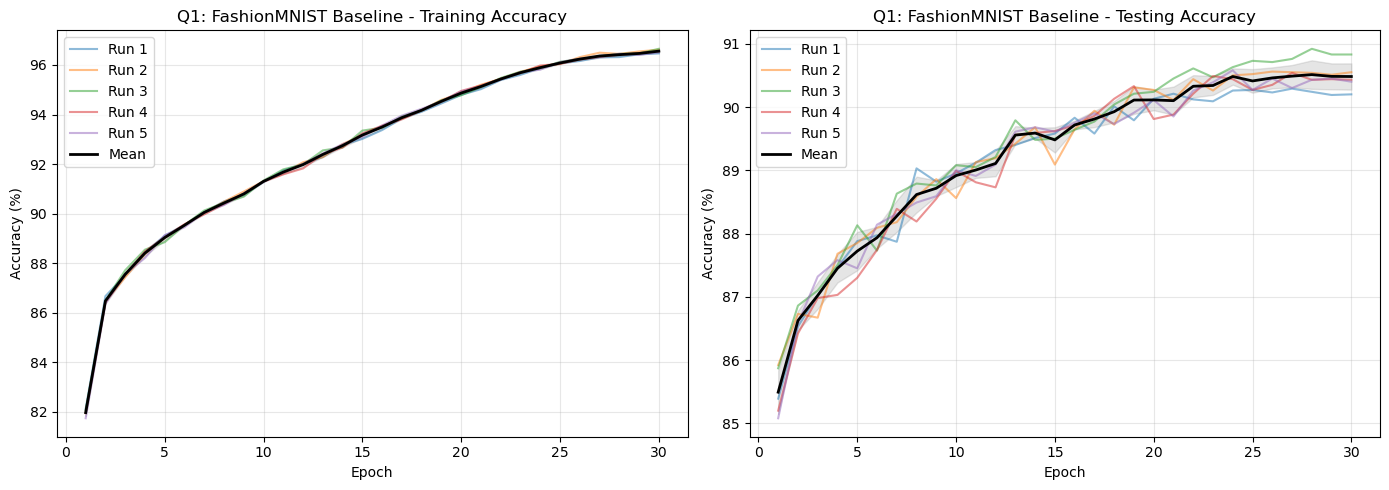


Q1: FashionMNIST Baseline - Final Converged Model Results (over 5 runs):
  Training Accuracy:  Mean = 96.56%, Variance = 0.0045
  Testing  Accuracy:  Mean = 90.48%, Variance = 0.0429


In [34]:
def plot_baseline_curves(train_acc, test_acc, title_prefix):
    """Plot training and testing accuracy curves for baseline runs."""
    num_runs, num_epochs = train_acc.shape
    epochs = range(1, num_epochs + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Training accuracy
    ax = axes[0]
    for run in range(num_runs):
        ax.plot(epochs, train_acc[run], alpha=0.5, label=f'Run {run+1}')
    mean_train = train_acc.mean(axis=0)
    std_train = train_acc.std(axis=0)
    ax.plot(epochs, mean_train, 'k-', linewidth=2, label='Mean')
    ax.fill_between(epochs, mean_train - std_train, mean_train + std_train, alpha=0.2, color='gray')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{title_prefix} - Training Accuracy')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Testing accuracy
    ax = axes[1]
    for run in range(num_runs):
        ax.plot(epochs, test_acc[run], alpha=0.5, label=f'Run {run+1}')
    mean_test = test_acc.mean(axis=0)
    std_test = test_acc.std(axis=0)
    ax.plot(epochs, mean_test, 'k-', linewidth=2, label='Mean')
    ax.fill_between(epochs, mean_test - std_test, mean_test + std_test, alpha=0.2, color='gray')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{title_prefix} - Testing Accuracy')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    final_train = train_acc[:, -1]
    final_test = test_acc[:, -1]
    print(f'\n{title_prefix} - Final Converged Model Results (over {num_runs} runs):')
    print(f'  Training Accuracy:  Mean = {final_train.mean():.2f}%, Variance = {final_train.var():.4f}')
    print(f'  Testing  Accuracy:  Mean = {final_test.mean():.2f}%, Variance = {final_test.var():.4f}')


plot_baseline_curves(q1_train_acc, q1_test_acc, 'Q1: FashionMNIST Baseline')

---
# Q2: FedAvg Implementation (FashionMNIST)

**Architecture:**
- **Server (main process):** Holds the global model, performs FedAvg aggregation, evaluates on validation set (convergence) AND test set (reporting) each round
- **5 Clients (simulated via iteration):** Per the project notes — *"To simulate multiple clients in one machine, you can create multiple threads or simply using iteration"* — each client trains locally on its own data partition

**Data split:** Randomly and unevenly divided per image label using Dirichlet distribution, no overlapping data samples across clients.

### Data Partitioning: Random & Uneven Split (Non-IID)

In [38]:
def get_targets(dataset):
    """
    Extract labels from a dataset (handles both raw datasets and Subset).
    """
    if isinstance(dataset, Subset):
        underlying = dataset.dataset
        if hasattr(underlying, 'targets'):
            all_targets = np.array(underlying.targets)
        else:
            all_targets = np.array([underlying[i][1] for i in range(len(underlying))])
        return all_targets[dataset.indices]
    elif hasattr(dataset, 'targets'):
        return np.array(dataset.targets)
    else:
        return np.array([dataset[i][1] for i in range(len(dataset))])


def split_data_uneven(dataset, num_clients=5, seed=42):
    """
    Split dataset randomly and unevenly for each label, with no overlap.

    For each class label:
      - Shuffle the indices
      - Generate random split proportions using Dirichlet(alpha=0.5)
      - alpha < 1 creates more uneven distributions
      - Assign samples to clients based on proportions

    Returns: list of index arrays, one per client (indices into the dataset).
    """
    np.random.seed(seed)
    labels = get_targets(dataset)
    num_classes = len(np.unique(labels))
    client_indices = [[] for _ in range(num_clients)]

    for c in range(num_classes):
        class_indices = np.where(labels == c)[0]
        np.random.shuffle(class_indices)

        proportions = np.random.dirichlet(np.ones(num_clients) * 0.5)
        split_points = (proportions * len(class_indices)).astype(int)
        split_points[-1] = len(class_indices) - split_points[:-1].sum()

        start = 0
        for i in range(num_clients):
            end = start + split_points[i]
            client_indices[i].extend(class_indices[start:end].tolist())
            start = end

    for i in range(num_clients):
        client_indices[i] = np.array(client_indices[i])
        np.random.shuffle(client_indices[i])

    return client_indices


def print_split_stats(dataset, client_indices, num_classes=10):
    """Print the data distribution across clients."""
    labels = get_targets(dataset)

    print(f"{'Client':<10}", end='')
    for c in range(num_classes):
        print(f"{'Class '+str(c):<10}", end='')
    print(f"{'Total':<10}")
    print('-' * (10 + 10 * num_classes + 10))

    for i, indices in enumerate(client_indices):
        client_labels = labels[indices]
        print(f"{'Client '+str(i+1):<10}", end='')
        for c in range(num_classes):
            count = (client_labels == c).sum()
            print(f"{count:<10}", end='')
        print(f"{len(indices):<10}")

In [18]:
# Demonstrate the uneven split
demo_indices = split_data_uneven(fashion_train, num_clients=5, seed=42)
print('FashionMNIST Training Data Split Across 5 Clients (Non-IID, Uneven):')
print_split_stats(fashion_train, demo_indices)

FashionMNIST Training Data Split Across 5 Clients (Non-IID, Uneven):
Client    Class 0   Class 1   Class 2   Class 3   Class 4   Class 5   Class 6   Class 7   Class 8   Class 9   Total     
------------------------------------------------------------------------------------------------------------------------
Client 1  2139      323       1424      85        1443      70        230       136       3303      1211      10364     
Client 2  1839      47        2528      4141      418       314       1032      378       2         384       11083     
Client 3  154       3734      34        214       593       1003      39        1191      1199      1236      9397      
Client 4  291       1206      78        57        63        2673      2641      1317      518       524       9368      
Client 5  1004      76        1343      862       2910      1336      1439      2390      400       2028      13788     


### FedAvg Algorithm

Each communication round:
1. Server sends global model weights to all clients
2. Each client trains locally for E epochs on its own data partition
3. Server collects updated weights from all clients
4. Server aggregates using weighted average (FedAvg — weights proportional to client dataset size)
5. Server evaluates aggregated model on **validation set** (convergence) and **test set** (reporting)

In [39]:
def fedavg_aggregate(global_model, client_state_dicts, client_data_sizes):
    """
    FedAvg aggregation: weighted average of client model parameters.
    Weights are proportional to each client's dataset size.
    """
    total_size = sum(client_data_sizes)
    global_dict = global_model.state_dict()

    for key in global_dict.keys():
        global_dict[key] = torch.zeros_like(global_dict[key], dtype=torch.float32)
        for i, client_sd in enumerate(client_state_dicts):
            weight = client_data_sizes[i] / total_size
            global_dict[key] += weight * client_sd[key].float()

    global_model.load_state_dict(global_dict)
    return global_model


def run_fedavg(train_dataset, val_dataset, test_dataset, model_class,
               num_clients=5, num_runs=5, num_rounds=50, local_epochs=5,
               batch_size=64, lr=0.01, convergence_patience=10, device='cpu'):
    """
    FedAvg algorithm.

    Server (main process):
      - Aggregates client models each round
      - Evaluates on VALIDATION set for convergence checking
      - Evaluates on TEST set each round for reporting curves

    Clients (simulated via iteration):
      - Each trains locally on its own data partition
      - Returns state_dict + per-round training accuracy

    Returns:
        all_client_train_acc: list of arrays (num_rounds, num_clients) per run
        all_server_val_acc:   list of arrays (num_rounds,) per run
        all_server_test_acc:  list of arrays (num_rounds,) per run
    """
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    criterion = nn.CrossEntropyLoss()

    all_client_train_acc = []
    all_server_val_acc = []
    all_server_test_acc = []

    for run in range(num_runs):
        set_seed(run * 42)
        print(f'\n--- FedAvg Run {run+1}/{num_runs} ---')

        # Split training data across clients (different random split each run)
        client_indices = split_data_uneven(train_dataset, num_clients, seed=run * 42)
        client_data_sizes = [len(indices) for indices in client_indices]
        print(f'  Client data sizes: {client_data_sizes}')

        # Create client dataloaders
        client_loaders = [
            DataLoader(Subset(train_dataset, indices.tolist()),
                       batch_size=batch_size, shuffle=True)
            for indices in client_indices
        ]

        # Initialize global model on server
        global_model = model_class().to(device)

        run_client_acc = []   # (num_rounds, num_clients)
        run_val_acc = []      # (num_rounds,)
        run_test_acc = []     # (num_rounds,)
        best_val_acc = 0.0
        patience_counter = 0

        for rnd in range(num_rounds):
            # ---- CLIENT LOCAL TRAINING (simulated via iteration) ----
            client_state_dicts = []
            round_client_acc = []

            for c in range(num_clients):
                # Each client gets a copy of the global model
                client_model = copy.deepcopy(global_model)
                client_model.train()
                optimizer = optim.SGD(client_model.parameters(), lr=lr, momentum=0.9)

                # Local training for E epochs
                total_correct, total_samples = 0, 0
                for epoch in range(local_epochs):
                    for data, target in client_loaders[c]:
                        data, target = data.to(device), target.to(device)
                        optimizer.zero_grad()
                        output = client_model(data)
                        loss = criterion(output, target)
                        loss.backward()
                        optimizer.step()
                        _, predicted = output.max(1)
                        total_correct += predicted.eq(target).sum().item()
                        total_samples += data.size(0)

                # Client training accuracy after local training this round
                train_acc = total_correct / total_samples * 100
                client_state_dicts.append(
                    {k: v.clone() for k, v in client_model.state_dict().items()}
                )
                round_client_acc.append(train_acc)

            # ---- SERVER AGGREGATION (FedAvg) ----
            global_model = fedavg_aggregate(global_model, client_state_dicts, client_data_sizes)

            # ---- SERVER EVALUATION ----
            # Validation: used for convergence checking
            val_loss, val_acc = evaluate(global_model, val_loader, criterion, device)
            # Test: evaluated each round for reporting curves
            test_loss, test_acc = evaluate(global_model, test_loader, criterion, device)

            run_client_acc.append(round_client_acc)
            run_val_acc.append(val_acc)
            run_test_acc.append(test_acc)

            if (rnd + 1) % 5 == 0 or rnd == 0:
                client_accs_str = ', '.join([f'{a:.1f}%' for a in round_client_acc])
                print(f'  Round {rnd+1}/{num_rounds}: '
                      f'Val: {val_acc:.2f}% | Test: {test_acc:.2f}% | '
                      f'Clients: [{client_accs_str}]')

            # Convergence check on VALIDATION accuracy
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= convergence_patience:
                print(f'  Converged at round {rnd+1} (patience={convergence_patience})')
                # Pad remaining rounds for consistent array shapes
                for _ in range(num_rounds - rnd - 1):
                    run_client_acc.append(round_client_acc)
                    run_val_acc.append(val_acc)
                    run_test_acc.append(test_acc)
                break

        all_client_train_acc.append(np.array(run_client_acc))
        all_server_val_acc.append(np.array(run_val_acc))
        all_server_test_acc.append(np.array(run_test_acc))
        print(f'--- Run {run+1} Final: Val: {run_val_acc[-1]:.2f}%, Test: {run_test_acc[-1]:.2f}% ---')

    return all_client_train_acc, all_server_val_acc, all_server_test_acc

In [40]:
print('='*60)
print('Q2: FedAvg - FashionMNIST')
print('='*60)
q2_client_acc, q2_val_acc, q2_test_acc = run_fedavg(
    fashion_train, fashion_val, fashion_test, TwoLayerNN,
    num_clients=5, num_runs=5, num_rounds=50, local_epochs=5,
    batch_size=64, lr=0.01, convergence_patience=10, device=device
)

Q2: FedAvg - FashionMNIST

--- FedAvg Run 1/5 ---
  Client data sizes: [7072, 8041, 9963, 14994, 13930]
  Round 1/50: Val: 82.20% | Test: 81.35% | Clients: [85.6%, 89.5%, 88.4%, 86.1%, 81.6%]
  Round 5/50: Val: 88.85% | Test: 87.66% | Clients: [93.9%, 96.0%, 94.9%, 92.4%, 88.6%]
  Round 10/50: Val: 89.23% | Test: 88.66% | Clients: [95.3%, 97.2%, 96.1%, 94.5%, 91.3%]
  Round 15/50: Val: 89.73% | Test: 88.95% | Clients: [96.1%, 97.7%, 96.9%, 95.7%, 93.0%]
  Round 20/50: Val: 89.72% | Test: 89.48% | Clients: [96.9%, 98.0%, 97.4%, 96.7%, 94.5%]
  Round 25/50: Val: 89.87% | Test: 89.25% | Clients: [97.2%, 98.5%, 97.7%, 97.3%, 95.3%]
  Round 30/50: Val: 89.97% | Test: 89.52% | Clients: [97.6%, 98.7%, 98.2%, 97.6%, 96.0%]
  Round 35/50: Val: 90.22% | Test: 89.56% | Clients: [97.8%, 98.9%, 98.3%, 98.0%, 96.7%]
  Round 40/50: Val: 90.27% | Test: 89.54% | Clients: [98.0%, 99.0%, 98.6%, 98.3%, 97.1%]
  Round 45/50: Val: 90.25% | Test: 89.43% | Clients: [98.2%, 99.1%, 98.7%, 98.5%, 97.5%]
  Conver

### Q2 Plots: Client Training Accuracy and Server Test Accuracy

To follow the project requirements, we plot:

- The training accuracy of each client over communication rounds
- The test accuracy of the aggregated global model evaluated on the server after each round

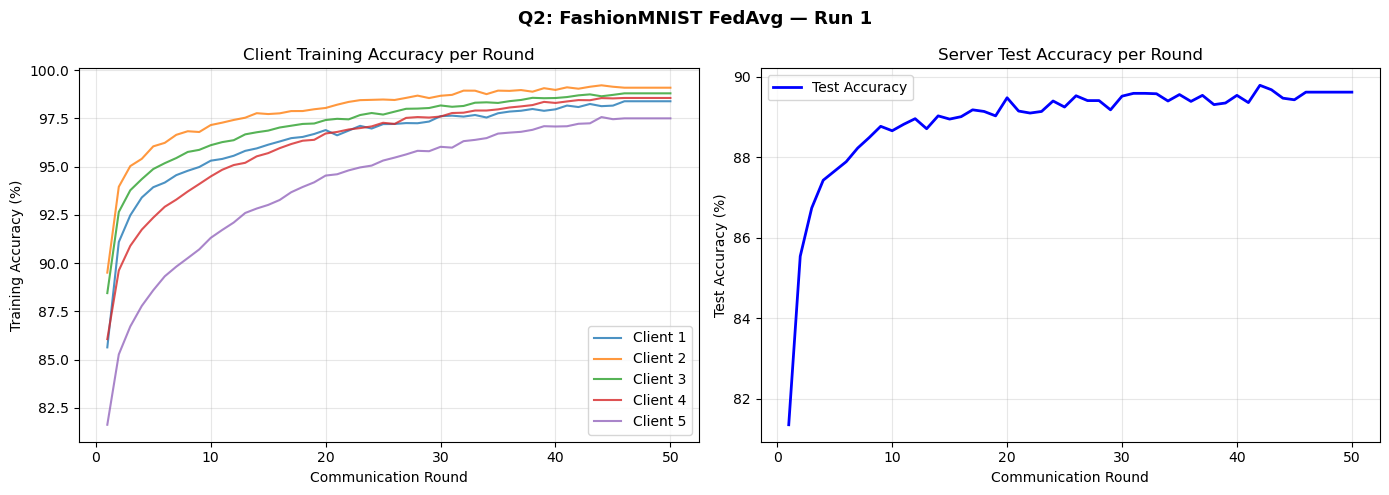

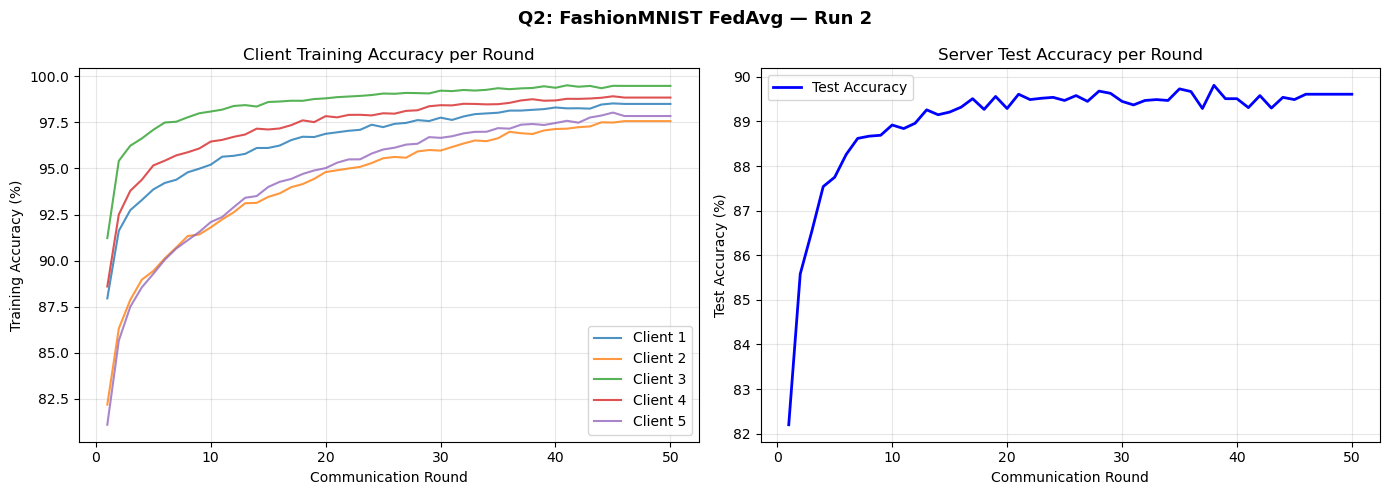

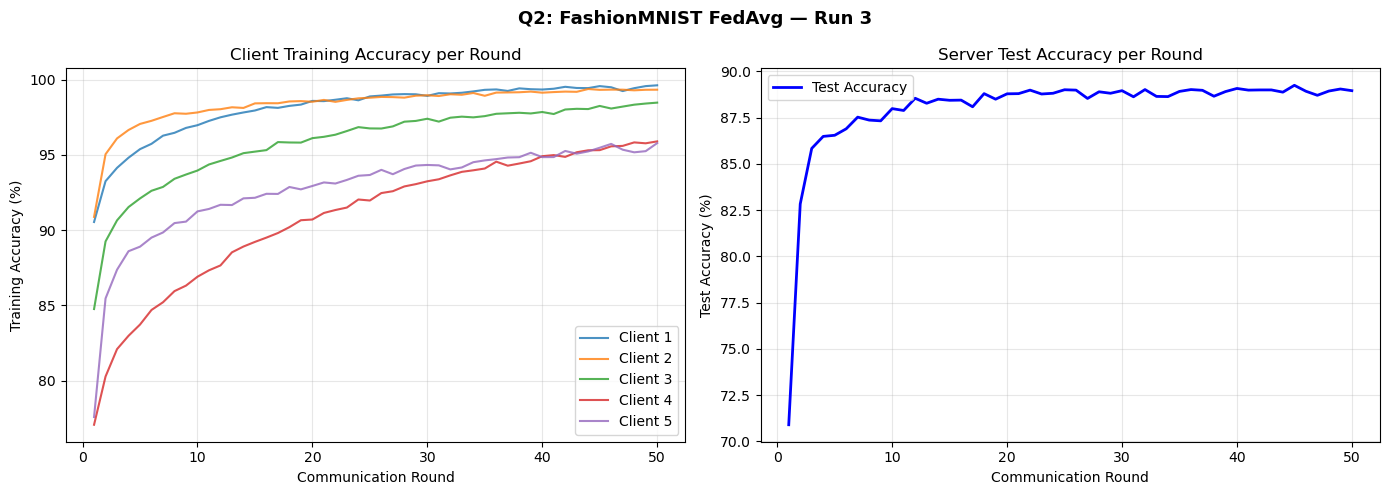

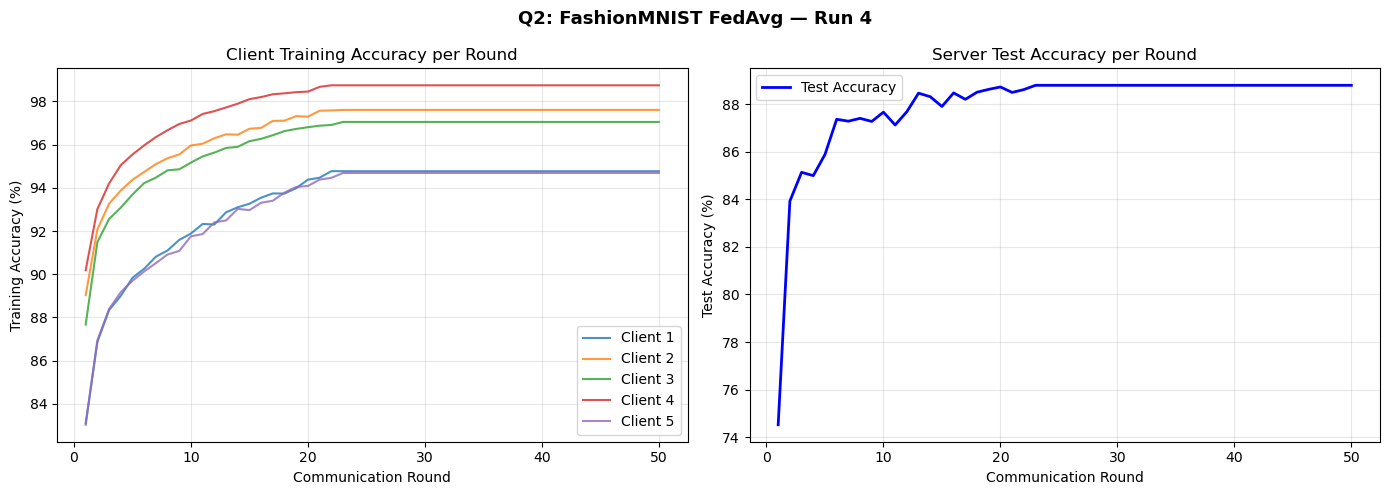

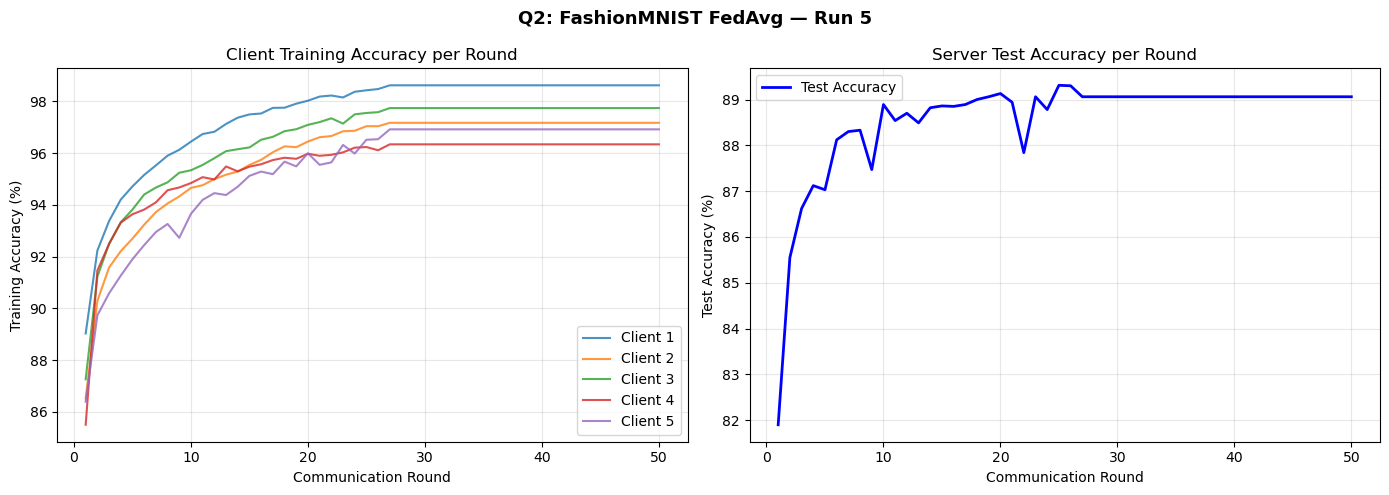

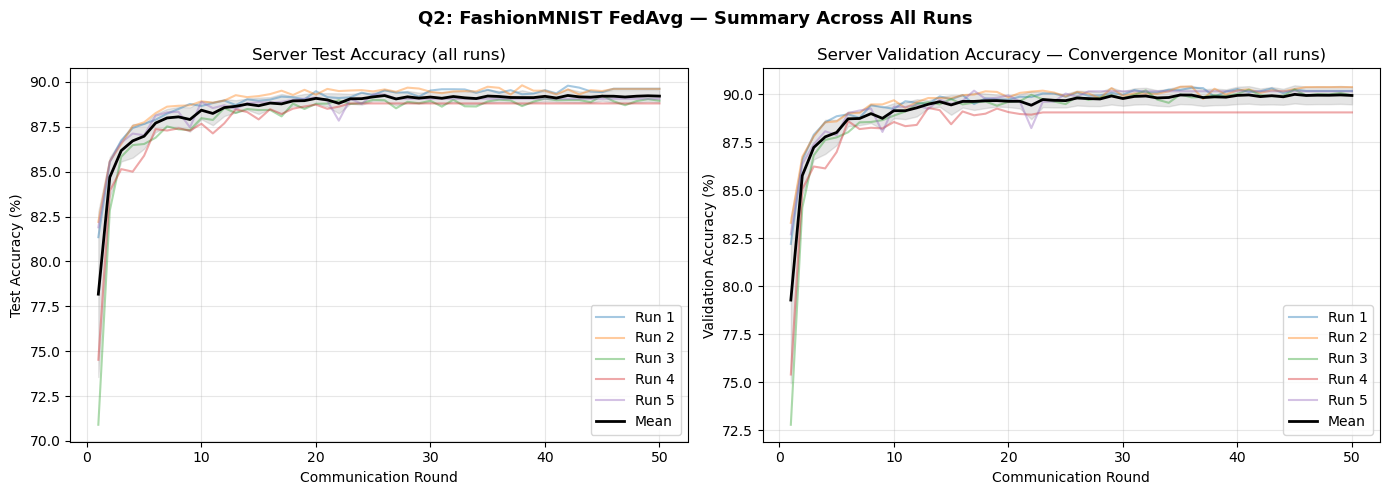


Q2: FashionMNIST FedAvg - Final Converged Model Results (over 5 runs):
  Validation Accuracy: Mean = 89.93%, Variance = 0.2139
  Test Accuracy:       Mean = 89.21%, Variance = 0.1173


In [41]:
def plot_fedavg_curves(client_train_acc_list, server_test_acc_list,
                       server_val_acc_list, title_prefix, num_clients=5):
    """
    Plot FedAvg training curves.

    For each run individually:
      - Left: Per-client training accuracy per communication round (not averaged)
      - Right: Server test accuracy per communication round

    Also plots a summary across all runs.

    client_train_acc_list: list of arrays, each (num_rounds, num_clients)
    server_test_acc_list:  list of arrays, each (num_rounds,)
    server_val_acc_list:   list of arrays, each (num_rounds,)
    """
    num_runs = len(client_train_acc_list)

    # --- Individual plots per run ---
    for run in range(num_runs):
        client_acc = client_train_acc_list[run]   # (num_rounds, num_clients)
        test_acc = server_test_acc_list[run]       # (num_rounds,)
        num_rounds_run = len(test_acc)
        rounds = range(1, num_rounds_run + 1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f'{title_prefix} — Run {run+1}', fontsize=13, fontweight='bold')

        # Left: Per-client training accuracy (individual, NOT averaged)
        ax = axes[0]
        for c in range(num_clients):
            ax.plot(rounds, client_acc[:, c], alpha=0.8, label=f'Client {c+1}')
        ax.set_xlabel('Communication Round')
        ax.set_ylabel('Training Accuracy (%)')
        ax.set_title('Client Training Accuracy per Round')
        ax.legend()
        ax.grid(True, alpha=0.3)

        # Right: Server test accuracy per round
        ax = axes[1]
        ax.plot(rounds, test_acc, 'b-', linewidth=2, label='Test Accuracy')
        ax.set_xlabel('Communication Round')
        ax.set_ylabel('Test Accuracy (%)')
        ax.set_title('Server Test Accuracy per Round')
        ax.legend()
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    # --- Summary plot across all runs ---
    stacked_test = np.array([acc for acc in server_test_acc_list])
    stacked_val = np.array([acc for acc in server_val_acc_list])
    num_rounds_total = stacked_test.shape[1]
    rounds = range(1, num_rounds_total + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'{title_prefix} — Summary Across All Runs', fontsize=13, fontweight='bold')

    # Left: Server test accuracy per run + mean
    ax = axes[0]
    for run in range(num_runs):
        ax.plot(rounds, stacked_test[run], alpha=0.4, label=f'Run {run+1}')
    mean_test = stacked_test.mean(axis=0)
    std_test = stacked_test.std(axis=0)
    ax.plot(rounds, mean_test, 'k-', linewidth=2, label='Mean')
    ax.fill_between(rounds, mean_test - std_test, mean_test + std_test, alpha=0.2, color='gray')
    ax.set_xlabel('Communication Round')
    ax.set_ylabel('Test Accuracy (%)')
    ax.set_title('Server Test Accuracy (all runs)')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Right: Server validation accuracy per run + mean
    ax = axes[1]
    for run in range(num_runs):
        ax.plot(rounds, stacked_val[run], alpha=0.4, label=f'Run {run+1}')
    mean_val = stacked_val.mean(axis=0)
    std_val = stacked_val.std(axis=0)
    ax.plot(rounds, mean_val, 'k-', linewidth=2, label='Mean')
    ax.fill_between(rounds, mean_val - std_val, mean_val + std_val, alpha=0.2, color='gray')
    ax.set_xlabel('Communication Round')
    ax.set_ylabel('Validation Accuracy (%)')
    ax.set_title('Server Validation Accuracy — Convergence Monitor (all runs)')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Report final stats
    final_val = stacked_val[:, -1]
    final_test = stacked_test[:, -1]
    print(f'\n{title_prefix} - Final Converged Model Results (over {num_runs} runs):')
    print(f'  Validation Accuracy: Mean = {final_val.mean():.2f}%, Variance = {final_val.var():.4f}')
    print(f'  Test Accuracy:       Mean = {final_test.mean():.2f}%, Variance = {final_test.var():.4f}')


plot_fedavg_curves(q2_client_acc, q2_test_acc, q2_val_acc,
                   'Q2: FashionMNIST FedAvg', num_clients=5)

### Q2: Comparison with Baseline


Comparison: FashionMNIST
Method                    Mean Acc (%)    Variance       
-------------------------------------------------------
Baseline (Test)           90.48           0.0429         
FedAvg (Validation)       89.93           0.2139         
FedAvg (Test)             89.21           0.1173         
Gap (Test)                -1.27          


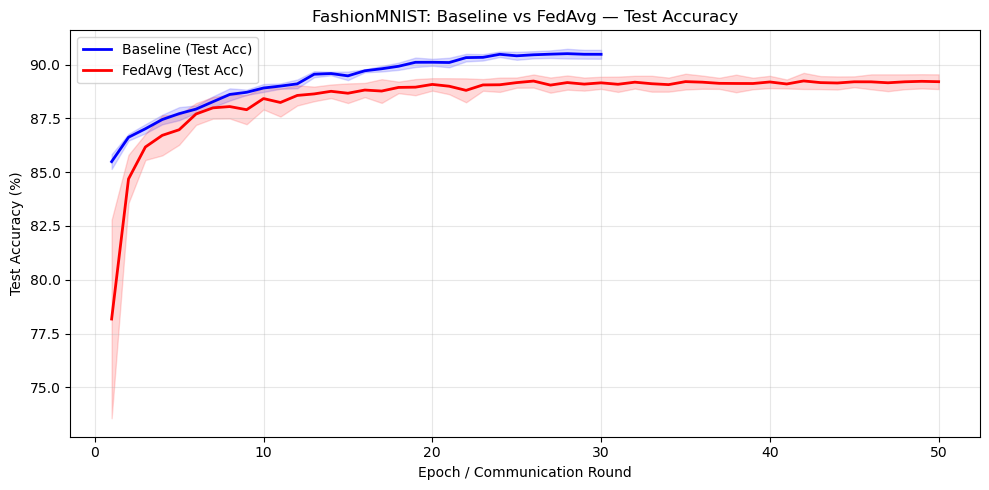

In [42]:
def compare_results(baseline_test_acc, fedavg_test_acc_list, fedavg_val_acc_list, dataset_name):
    """
    Compare baseline vs FedAvg results.
    baseline_test_acc: (num_runs, num_epochs)
    fedavg_test_acc_list: list of arrays, each (num_rounds,)
    fedavg_val_acc_list: list of arrays, each (num_rounds,)
    """
    baseline_final = baseline_test_acc[:, -1]
    stacked_fedavg_test = np.array(fedavg_test_acc_list)
    stacked_fedavg_val = np.array(fedavg_val_acc_list)
    fedavg_final_test = stacked_fedavg_test[:, -1]
    fedavg_final_val = stacked_fedavg_val[:, -1]

    print(f'\n{"="*60}')
    print(f'Comparison: {dataset_name}')
    print(f'{"="*60}')
    print(f'{"Method":<25} {"Mean Acc (%)":<15} {"Variance":<15}')
    print(f'{"-"*55}')
    print(f'{"Baseline (Test)":<25} {baseline_final.mean():<15.2f} {baseline_final.var():<15.4f}')
    print(f'{"FedAvg (Validation)":<25} {fedavg_final_val.mean():<15.2f} {fedavg_final_val.var():<15.4f}')
    print(f'{"FedAvg (Test)":<25} {fedavg_final_test.mean():<15.2f} {fedavg_final_test.var():<15.4f}')
    print(f'{"Gap (Test)":<25} {fedavg_final_test.mean() - baseline_final.mean():<+15.2f}')

    # Combined plot: Baseline test vs FedAvg test over epochs/rounds
    fig, ax = plt.subplots(figsize=(10, 5))

    # Baseline
    epochs = range(1, baseline_test_acc.shape[1] + 1)
    mean_baseline = baseline_test_acc.mean(axis=0)
    std_baseline = baseline_test_acc.std(axis=0)
    ax.plot(epochs, mean_baseline, 'b-', linewidth=2, label='Baseline (Test Acc)')
    ax.fill_between(epochs, mean_baseline - std_baseline, mean_baseline + std_baseline,
                    alpha=0.15, color='blue')

    # FedAvg test accuracy over communication rounds
    num_rounds = stacked_fedavg_test.shape[1]
    rounds = range(1, num_rounds + 1)
    mean_fedavg = stacked_fedavg_test.mean(axis=0)
    std_fedavg = stacked_fedavg_test.std(axis=0)
    ax.plot(rounds, mean_fedavg, 'r-', linewidth=2, label='FedAvg (Test Acc)')
    ax.fill_between(rounds, mean_fedavg - std_fedavg, mean_fedavg + std_fedavg,
                    alpha=0.15, color='red')

    ax.set_xlabel('Epoch / Communication Round')
    ax.set_ylabel('Test Accuracy (%)')
    ax.set_title(f'{dataset_name}: Baseline vs FedAvg — Test Accuracy')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


compare_results(q1_test_acc, q2_test_acc, q2_val_acc, 'FashionMNIST')

---
# Q3: CIFAR-10 — Baseline & FedAvg

Repeat Q1 and Q2 using CIFAR-10 dataset with a small CNN model.

### Q3a: CIFAR-10 Baseline

Q3a: Baseline Centralized Training - CIFAR-10
  Run 1/5, Epoch 1/20: Train Acc: 45.05%, Test Acc: 58.90%
  Run 1/5, Epoch 2/20: Train Acc: 62.65%, Test Acc: 66.16%
  Run 1/5, Epoch 3/20: Train Acc: 69.43%, Test Acc: 65.49%
  Run 1/5, Epoch 4/20: Train Acc: 74.24%, Test Acc: 71.09%
  Run 1/5, Epoch 5/20: Train Acc: 78.28%, Test Acc: 72.18%
  Run 1/5, Epoch 6/20: Train Acc: 82.19%, Test Acc: 72.40%
  Run 1/5, Epoch 7/20: Train Acc: 85.30%, Test Acc: 72.38%
  Run 1/5, Epoch 8/20: Train Acc: 88.65%, Test Acc: 71.61%
  Run 1/5, Epoch 9/20: Train Acc: 91.31%, Test Acc: 72.87%
  Run 1/5, Epoch 10/20: Train Acc: 93.62%, Test Acc: 71.84%
  Run 1/5, Epoch 11/20: Train Acc: 95.45%, Test Acc: 71.12%
  Run 1/5, Epoch 12/20: Train Acc: 96.41%, Test Acc: 71.72%
  Run 1/5, Epoch 13/20: Train Acc: 96.68%, Test Acc: 71.60%
  Run 1/5, Epoch 14/20: Train Acc: 97.24%, Test Acc: 71.34%
  Run 1/5, Epoch 15/20: Train Acc: 97.99%, Test Acc: 71.69%
  Run 1/5, Epoch 16/20: Train Acc: 98.69%, Test Acc: 71.93%
  R

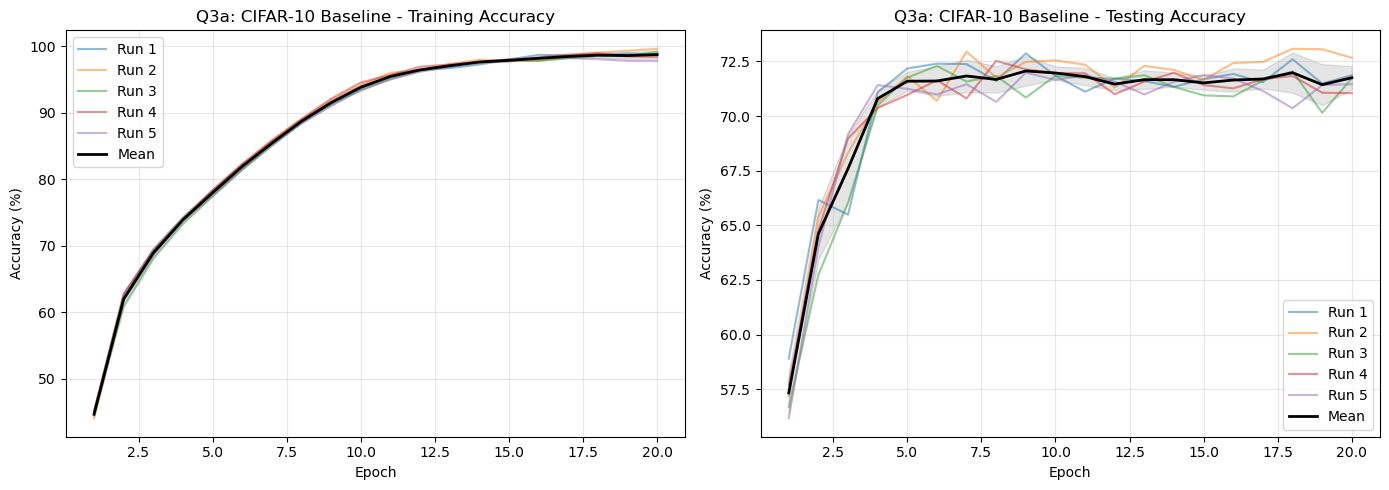


Q3a: CIFAR-10 Baseline - Final Converged Model Results (over 5 runs):
  Training Accuracy:  Mean = 98.73%, Variance = 0.3933
  Testing  Accuracy:  Mean = 71.76%, Variance = 0.2870


In [25]:
print('='*60)
print('Q3a: Baseline Centralized Training - CIFAR-10')
print('='*60)
q3a_train_acc, q3a_test_acc = run_baseline(
    cifar_full, cifar_test, SmallCNN_CIFAR,
    num_runs=5, num_epochs=20, batch_size=64, lr=0.01, device=device
)
plot_baseline_curves(q3a_train_acc, q3a_test_acc, 'Q3a: CIFAR-10 Baseline')

### Q3b: CIFAR-10 FedAvg

Q3b: FedAvg - CIFAR-10

--- FedAvg Run 1/5 ---
  Client data sizes: [11184, 1852, 16382, 4355, 11227]
  Round 1/50: Val: 49.12% | Test: 49.02% | Clients: [64.4%, 47.4%, 57.8%, 51.9%, 69.1%]
  Round 5/50: Val: 67.30% | Test: 67.96% | Clients: [94.7%, 91.6%, 95.7%, 91.1%, 96.0%]
  Round 10/50: Val: 67.92% | Test: 68.45% | Clients: [98.9%, 92.8%, 99.9%, 94.3%, 98.7%]
  Round 15/50: Val: 68.44% | Test: 68.44% | Clients: [99.6%, 93.7%, 100.0%, 96.6%, 99.7%]
  Round 20/50: Val: 67.92% | Test: 68.32% | Clients: [99.9%, 94.9%, 100.0%, 98.9%, 99.9%]
  Round 25/50: Val: 67.80% | Test: 68.46% | Clients: [99.9%, 97.3%, 100.0%, 99.5%, 99.9%]
  Converged at round 25 (patience=10)
--- Run 1 Final: Val: 67.80%, Test: 68.46% ---

--- FedAvg Run 2/5 ---
  Client data sizes: [9017, 5268, 12635, 7713, 10367]
  Round 1/50: Val: 36.26% | Test: 36.76% | Clients: [60.7%, 61.4%, 68.0%, 57.1%, 68.5%]
  Round 5/50: Val: 66.28% | Test: 66.48% | Clients: [93.4%, 93.2%, 94.4%, 89.7%, 95.5%]
  Round 10/50: Val: 67.8

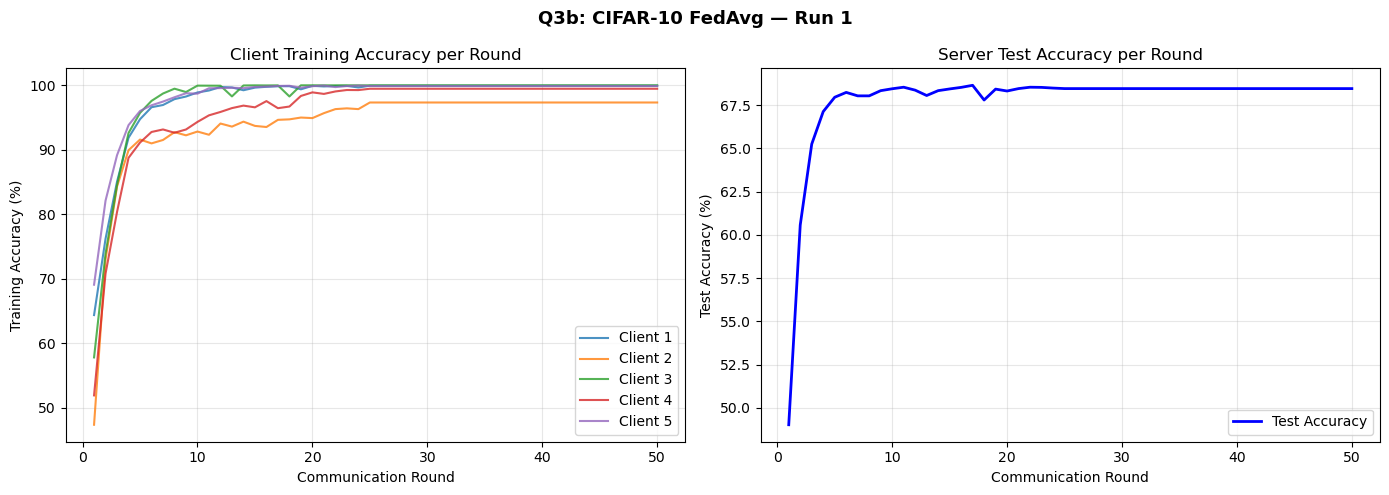

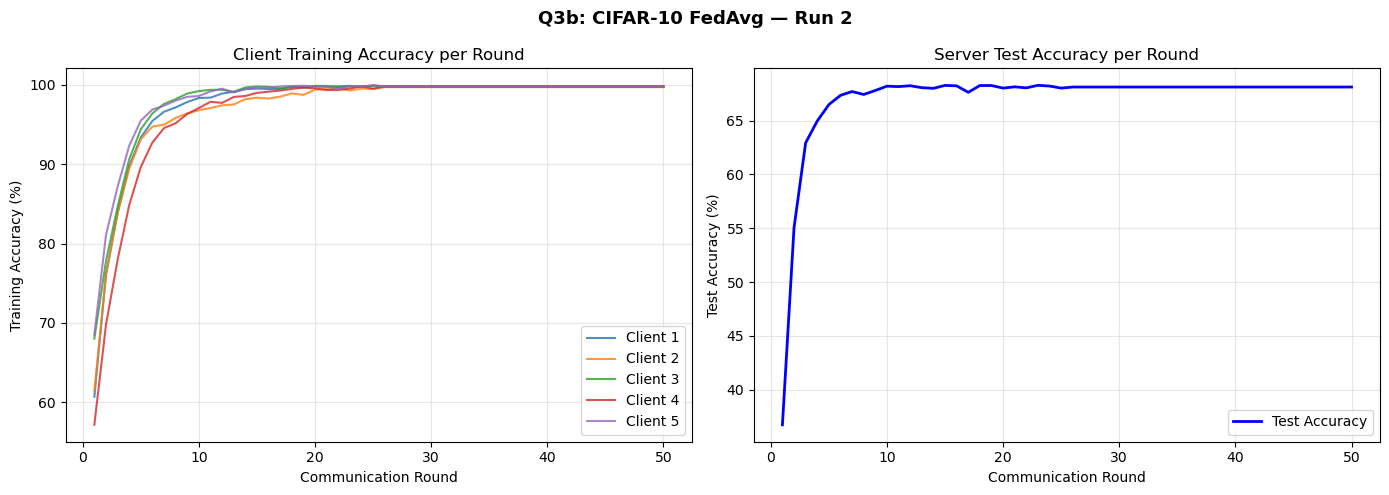

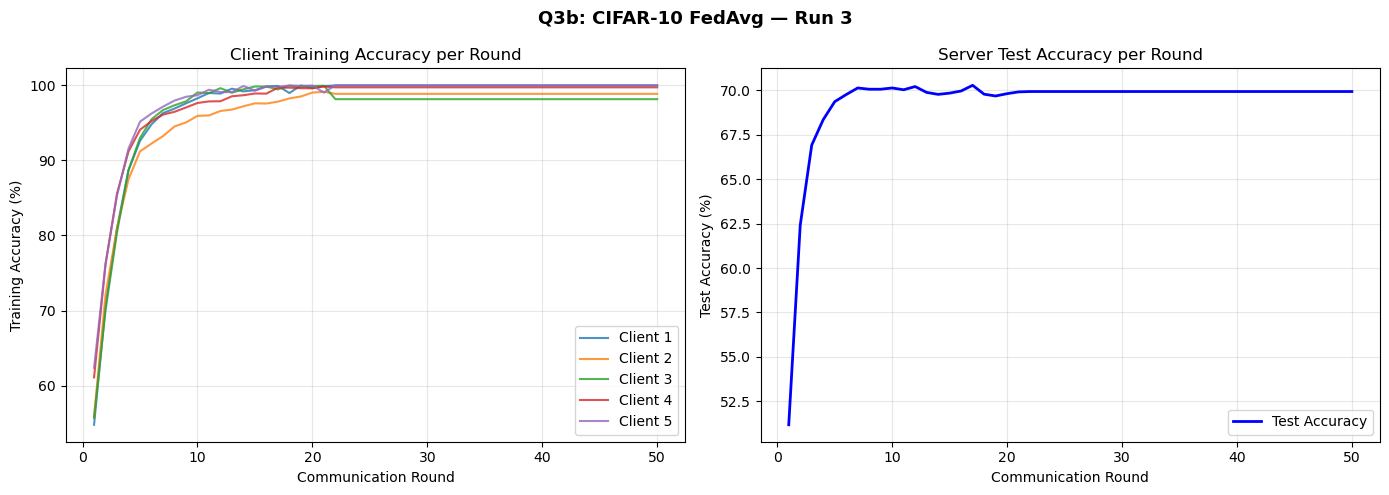

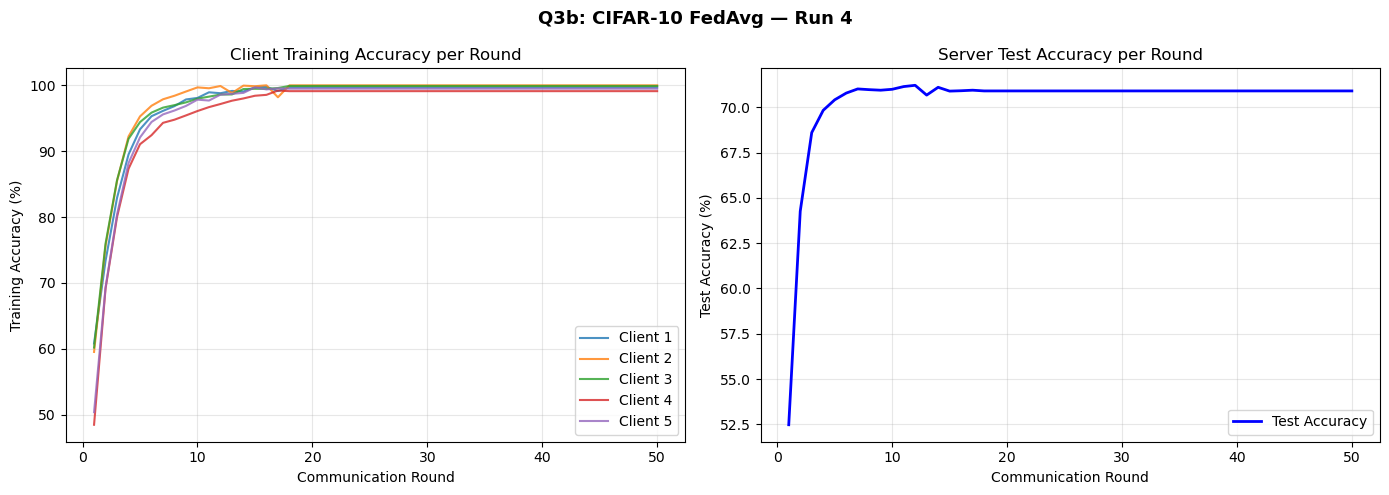

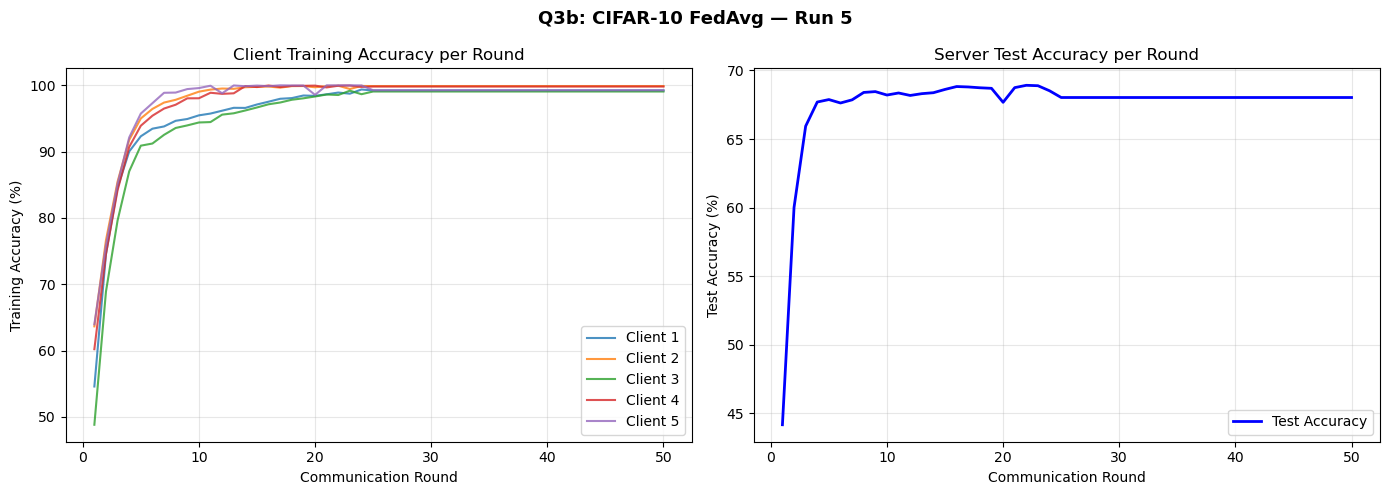

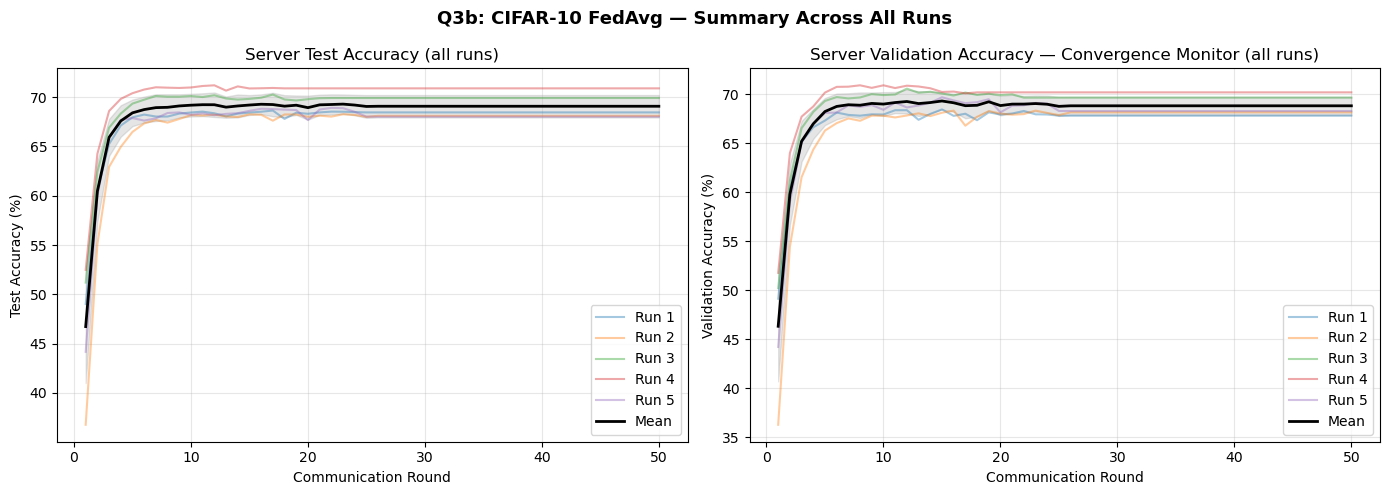


Q3b: CIFAR-10 FedAvg - Final Converged Model Results (over 5 runs):
  Validation Accuracy: Mean = 68.81%, Variance = 0.8631
  Test Accuracy:       Mean = 69.08%, Variance = 1.2891


In [26]:
print('='*60)
print('Q3b: FedAvg - CIFAR-10')
print('='*60)
q3b_client_acc, q3b_val_acc, q3b_test_acc = run_fedavg(
    cifar_train, cifar_val, cifar_test, SmallCNN_CIFAR,
    num_clients=5, num_runs=5, num_rounds=50, local_epochs=5,
    batch_size=64, lr=0.01, convergence_patience=10, device=device
)
plot_fedavg_curves(q3b_client_acc, q3b_test_acc, q3b_val_acc,
                   'Q3b: CIFAR-10 FedAvg', num_clients=5)

### Q3: Comparisons


Comparison: CIFAR-10
Method                    Mean Acc (%)    Variance       
-------------------------------------------------------
Baseline (Test)           71.76           0.2870         
FedAvg (Validation)       68.81           0.8631         
FedAvg (Test)             69.08           1.2891         
Gap (Test)                -2.67          


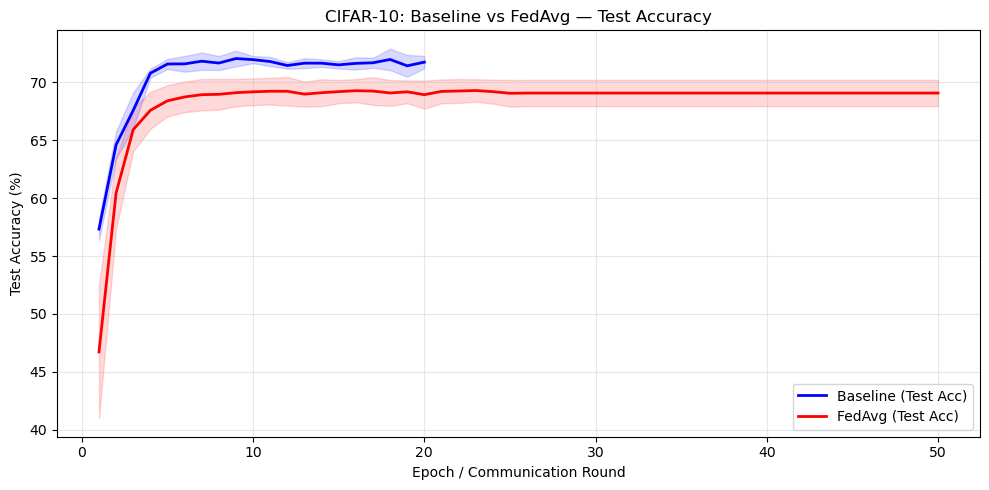

In [27]:
# CIFAR-10: Baseline vs FedAvg
compare_results(q3a_test_acc, q3b_test_acc, q3b_val_acc, 'CIFAR-10')


Cross-Dataset Comparison Summary
Method                    Mean Acc (%)    Std Dev         Variance       
----------------------------------------------------------------------
FashionMNIST Baseline     88.75           0.2745          0.0753         
FashionMNIST FedAvg       88.11           0.3647          0.1330         
CIFAR-10 Baseline         71.76           0.5357          0.2870         
CIFAR-10 FedAvg           69.08           1.1354          1.2891         


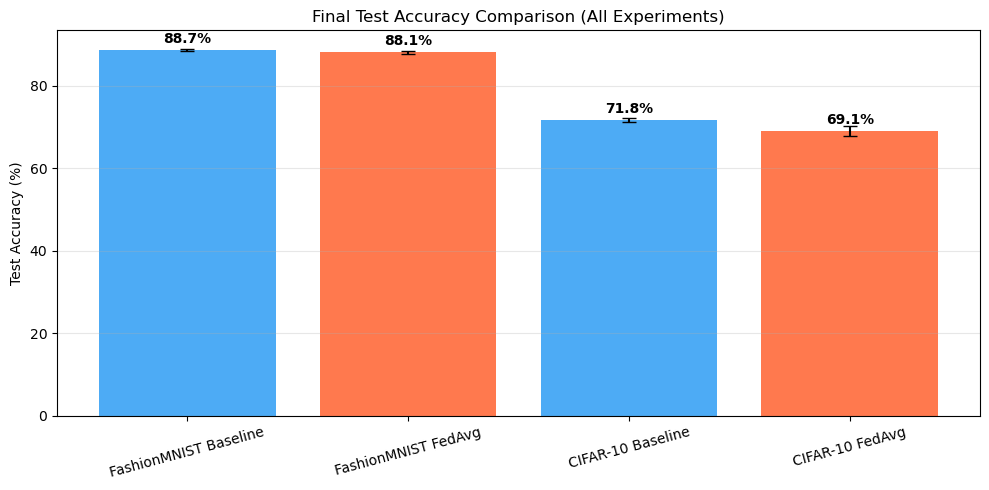

In [28]:
# Cross-dataset comparison
print('\n' + '='*60)
print('Cross-Dataset Comparison Summary')
print('='*60)

stacked_q2_test = np.array(q2_test_acc)
stacked_q3b_test = np.array(q3b_test_acc)

results = {
    'FashionMNIST Baseline': q1_test_acc[:, -1],
    'FashionMNIST FedAvg':   stacked_q2_test[:, -1],
    'CIFAR-10 Baseline':     q3a_test_acc[:, -1],
    'CIFAR-10 FedAvg':       stacked_q3b_test[:, -1],
}

print(f'{"Method":<25} {"Mean Acc (%)":<15} {"Std Dev":<15} {"Variance":<15}')
print('-' * 70)
for name, accs in results.items():
    print(f'{name:<25} {accs.mean():<15.2f} {accs.std():<15.4f} {accs.var():<15.4f}')

# Bar chart comparison
fig, ax = plt.subplots(figsize=(10, 5))
names = list(results.keys())
means = [v.mean() for v in results.values()]
stds = [v.std() for v in results.values()]
colors = ['#2196F3', '#FF5722', '#2196F3', '#FF5722']
bars = ax.bar(names, means, yerr=stds, capsize=5, color=colors, alpha=0.8)
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Final Test Accuracy Comparison (All Experiments)')
ax.grid(True, alpha=0.3, axis='y')
for bar, mean in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{mean:.1f}%', ha='center', va='bottom', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

---
## Observations and Conclusions (Updated with Latest Results)

### Experimental Summary

After optimization, we repeated each experiment 5 times and compared centralized baseline training with FedAvg under non-IID client splits.
For fairness in FashionMNIST, Q1 and Q2 use the same optimized model class (`TwoLayerNN`) and differ only in training setting (centralized vs federated).

### Q2 Results: FashionMNIST (Baseline vs FedAvg)

- **Baseline (Test):** Mean = **90.48%**, Variance = **0.0429**
- **FedAvg (Validation):** Mean = **89.93%**, Variance = **0.2139**
- **FedAvg (Test):** Mean = **89.21%**, Variance = **0.1173**
- **Test Accuracy Gap (FedAvg - Baseline):** **-1.27%**

**Observations (FashionMNIST):**
1. Baseline and FedAvg are close, but baseline still achieves the highest final test accuracy.
2. FedAvg has higher variance, indicating stronger sensitivity to random non-IID client splits.
3. FedAvg improves quickly in early rounds and then stabilizes slightly below baseline.
4. Optimization improves absolute performance, but non-IID heterogeneity still causes a persistent gap.

### Q3 Results: CIFAR-10 (Baseline vs FedAvg)

- **Baseline (Test):** Mean = **71.76%**, Variance = **0.2870**
- **FedAvg (Validation):** Mean = **68.81%**, Variance = **0.8631**
- **FedAvg (Test):** Mean = **69.08%**, Variance = **1.2891**
- **Test Accuracy Gap (FedAvg - Baseline):** **-2.67%**

**Observations (CIFAR-10):**
1. CIFAR-10 remains significantly harder than FashionMNIST for both centralized and federated training.
2. The baseline-FedAvg gap is larger than in FashionMNIST.
3. FedAvg variance is much higher on CIFAR-10, showing lower stability across runs.
4. Harder task complexity amplifies client drift and non-IID effects in federated learning.

### Cross-Dataset Comparison

- **FashionMNIST Baseline:** 90.48% (Std 0.2071)
- **FashionMNIST FedAvg:** 89.21% (Std 0.3425)
- **CIFAR-10 Baseline:** 71.76% (Std 0.5357)
- **CIFAR-10 FedAvg:** 69.08% (Std 1.1354)

### Final Conclusions

1. **FedAvg is effective but has a cost:** it enables collaborative training without sharing raw data, but usually sacrifices some accuracy compared with centralized learning.
2. **Non-IID data is the key challenge:** uneven label distributions across clients are the primary reason for accuracy degradation and higher variance.
3. **Dataset complexity matters:** federated performance drops more on harder tasks (CIFAR-10), where optimization is less stable.
4. **Optimization helps but does not fully close the gap:** after tuning, FashionMNIST baseline reaches >90%, but federated results still trail baseline.
5. **Practical implication:** careful tuning of local epochs, learning rate scheduling, and heterogeneity-aware methods is necessary to approach centralized performance in federated settings.